# Required MNIST rerun: 9,000 training / 1,000 validation

This is the requested smaller-data experiment. The earlier 54,000/6,000 run is preserved as a separate historical experiment. This notebook reads saved results only: no retraining, downloads or official test evaluation.

The exact 10,000 selected training-source rows are recorded in `membership.json`. Split seed 42 fixes selection and membership; stream seed 42 fixes training order. Remaining training-source rows are unused. All ten digits are mixed; images remain 28x28 grayscale scaled to [0,1], with identity model normalization. SmallResNet has one input channel and ten outputs; Adam 0.001, batch 32, one pass, no replay/pretraining.

The sample counts now match the CIFAR debugging experiment. Different datasets, class counts, preprocessing and models still prevent treating GaussianNB as a controlled SmallResNet dataset comparison.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "configs/mnist_9000.yaml").is_file())
RUN = ROOT / "results/mnist_9000_seed42"
rows = pd.read_csv(RUN / "results.csv")
meta = json.loads((RUN / "run.json").read_text())
membership = json.loads((RUN / "membership.json").read_text())
audit = json.loads((RUN / "audit/audit.json").read_text())
train, val = membership["train_stream_rows"], membership["validation_rows"]
assert len(train) == len(set(train)) == 9000
assert len(val) == len(set(val)) == 1000
assert not set(train) & set(val)
assert len(set(train) | set(val)) == 10000
assert set(train) | set(val) <= set(range(60000))
final = rows.iloc[-1]
assert final.examples_processed == meta["examples_processed"] == 9000
assert final.updates == meta["updates"] == 282
assert meta["config"]["train_size"] == 9000 and meta["config"]["validation_size"] == 1000
assert audit["validation_examples"] == 1000
assert audit["model_state_unchanged"] and audit["loader_membership_matches"]
assert not audit["official_test_set_used"]
for name, value in audit["metrics"].items():
    assert abs(value-float(final[name])) < 1e-12
print("9,000 train + 1,000 validation; zero overlap; 282 updates; final batch 8")
print(f"Checkpoint reproduced: {audit['correct']} correct; {audit['mistakes']} errors / 1,000")
display(pd.DataFrame([{
    "Accuracy (%)": 100*final.accuracy, "Macro precision (%)": 100*final.precision,
    "Macro recall (%)": 100*final.recall, "Macro F1": final.f1,
    "Training compute (s)": meta["training_seconds"],
    "Run wall time (s)": meta["total_wall_seconds"], "Device": meta["device"]
}]).round(4))

9,000 train + 1,000 validation; zero overlap; 282 updates; final batch 8
Checkpoint reproduced: 964 correct; 36 errors / 1,000


,Accuracy (%),Macro precision (%),Macro recall (%),Macro F1,Training compute (s),Run wall time (s),Device
0,96.4,96.5681,96.2644,0.9633,133.0663,194.6195,cpu


## Learning with 9,000 examples

These are validation measurements at complete-batch boundaries near every 1,000 examples. The final checkpoint is reported, not a chosen peak. The 1,000 validation images are not used for optimization. One seed supports a single-run result, not a robust mean estimate.

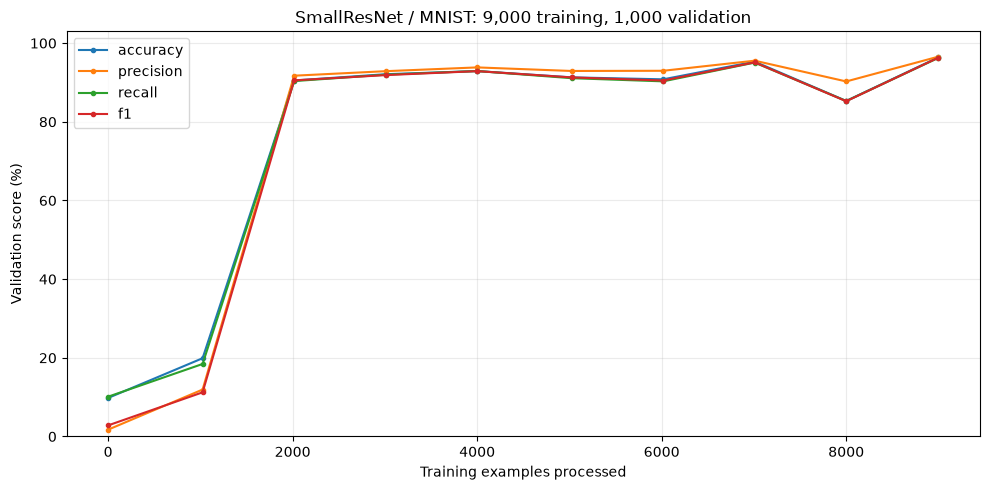

Final accuracy: 96.40%; macro F1: 0.9633


In [2]:
fig, ax = plt.subplots(figsize=(10,5))
for metric in ("accuracy","precision","recall","f1"):
    ax.plot(rows.examples_processed, 100*rows[metric], marker=".", label=metric)
ax.set(xlabel="Training examples processed", ylabel="Validation score (%)", ylim=(0,103),
       title="SmallResNet / MNIST: 9,000 training, 1,000 validation")
ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
print(f"Final accuracy: {100*final.accuracy:.2f}%; macro F1: {final.f1:.4f}")

## Training-count context

Left: two MNIST runs with the same model/configuration except sample counts and resulting memberships. They use different validation sets, so this is descriptive rather than an isolated causal estimate of extra training data. Right: the available CIFAR GaussianNB run, with the same 9,000/1,000 counts but a different model, dataset, and number of classes. Do not interpret the gap as a fair model ranking.

The requested **SmallResNet on MNIST versus SmallResNet on CIFAR** comparison remains pending Nguyen's original online CIFAR CSV/configuration and timing details. No informal accuracy is substituted for a source artifact.

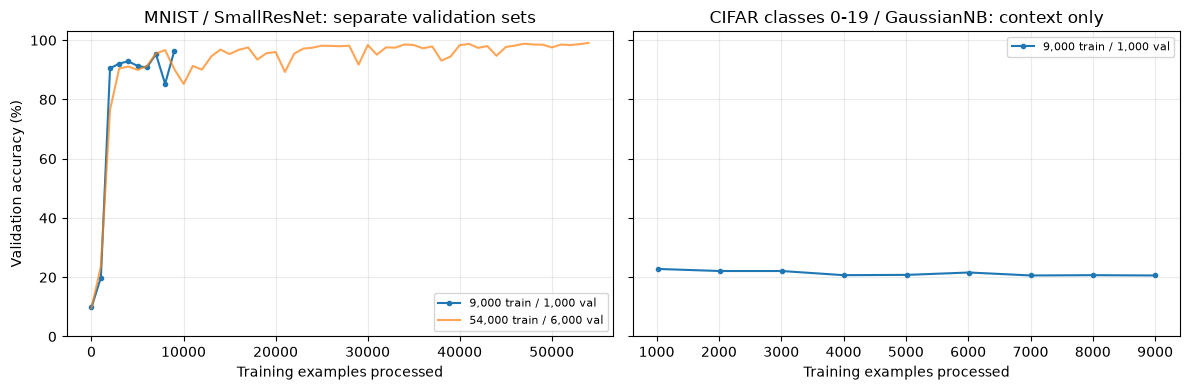

In [3]:
old = pd.read_csv(ROOT / "results/mnist_seed42_complete/results.csv")
cf = pd.read_csv(ROOT / "results/gaussiannb_results.csv")
fig, axes = plt.subplots(1,2,figsize=(12,4),sharey=True)
axes[0].plot(rows.examples_processed,100*rows.accuracy,marker=".",label="9,000 train / 1,000 val")
axes[0].plot(old.examples_processed,100*old.accuracy,label="54,000 train / 6,000 val",alpha=.7)
axes[0].set_title("MNIST / SmallResNet: separate validation sets")
axes[0].legend(fontsize=8)
axes[1].plot(cf.examples_processed,100*cf.accuracy,marker=".",label="9,000 train / 1,000 val")
axes[1].set_title("CIFAR classes 0-19 / GaussianNB: context only")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set(xlabel="Training examples processed",ylim=(0,103)); ax.grid(alpha=.25)
axes[0].set_ylabel("Validation accuracy (%)")
fig.tight_layout(); plt.show()

## Independent saved-checkpoint verification

The model was reloaded from its checkpoint and evaluated directly on the saved validation row IDs. All final metrics match within 1e-12; training and validation memberships agree with configured loaders; model state is unchanged. The audit uses the training-source validation subset only, never the official test set. The figures show all confusion counts and the first up to 20 errors in saved order.

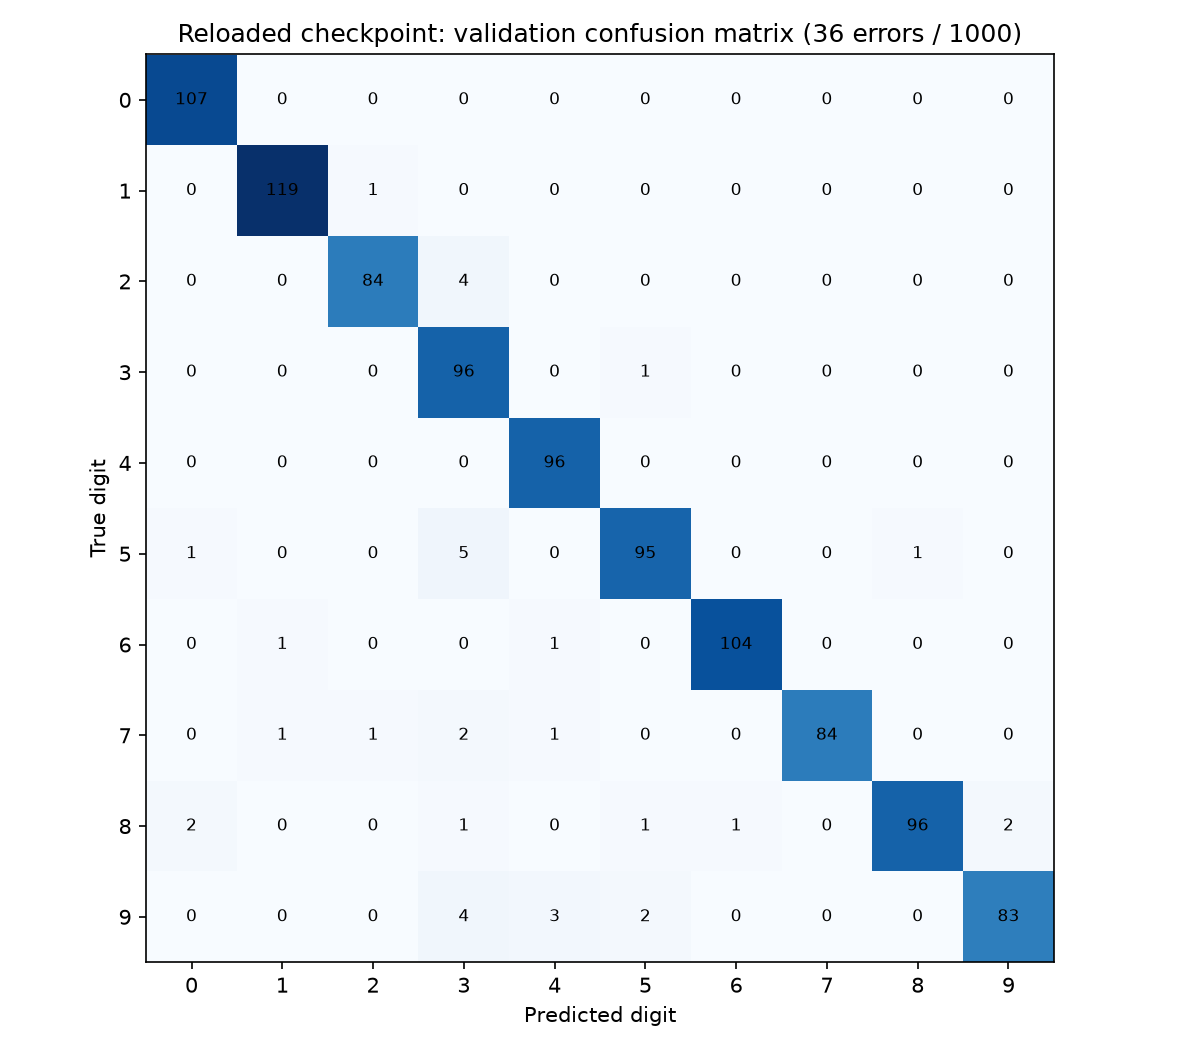

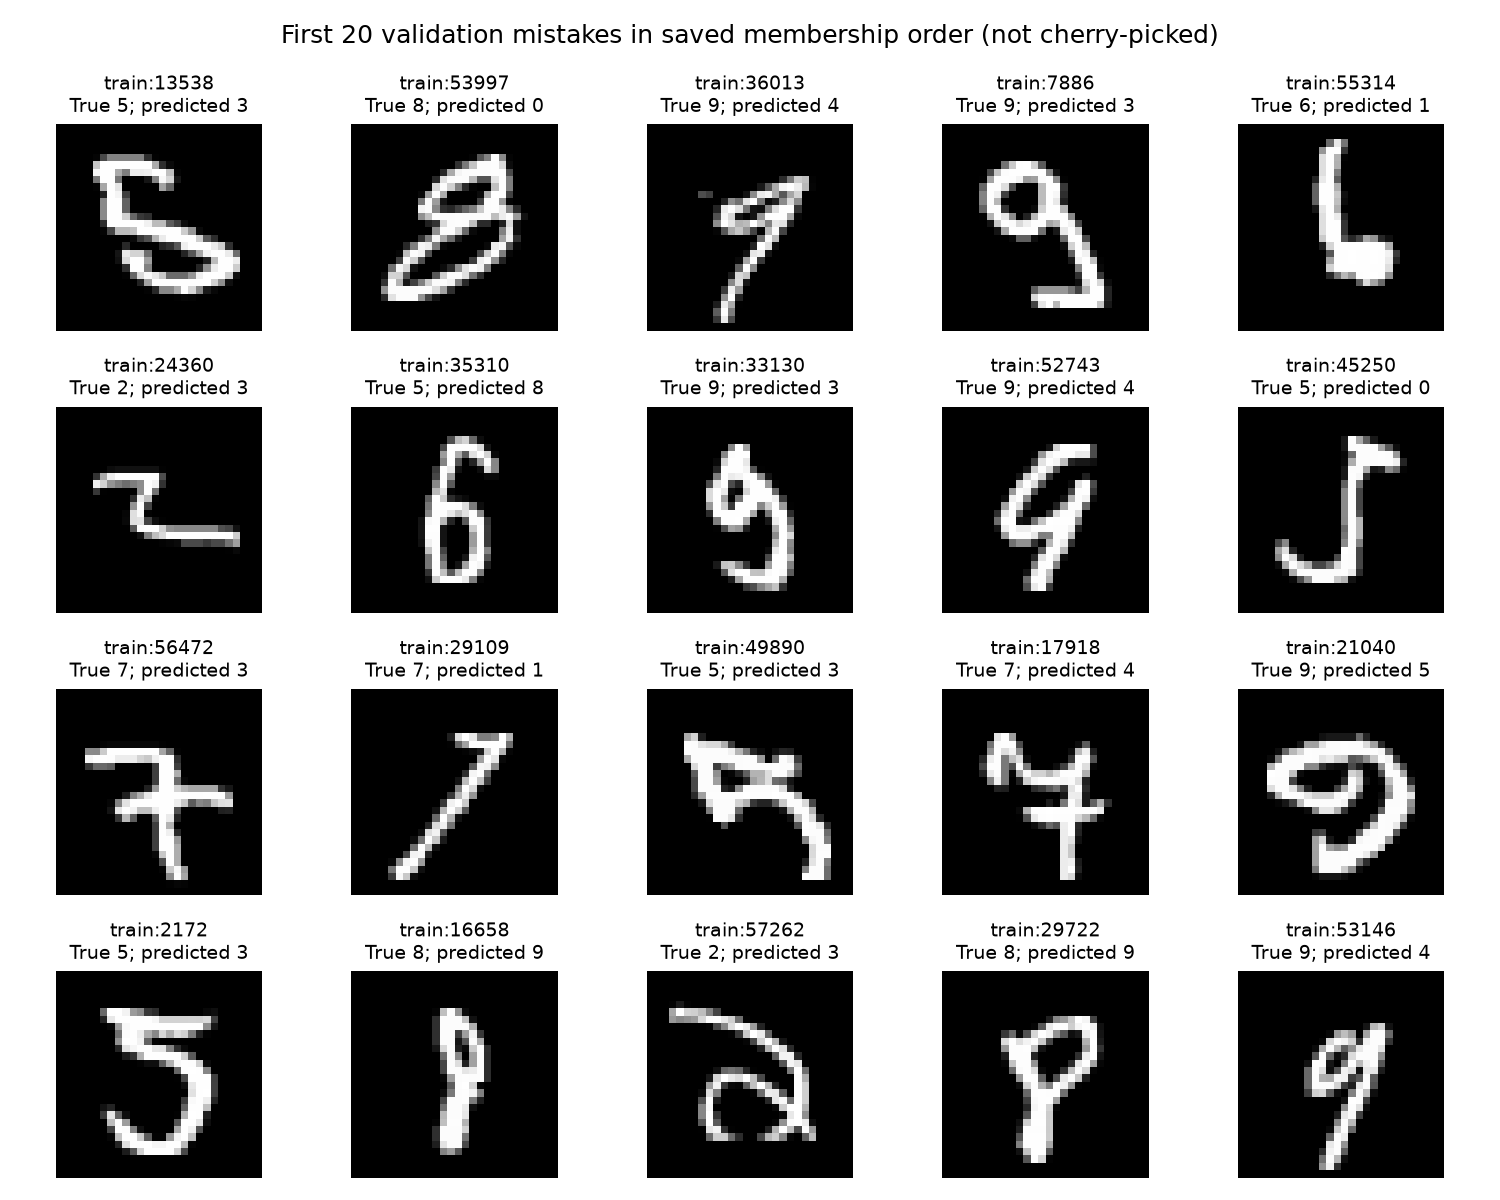

Checkpoint SHA-256: 11447cbef2653c458c4d20a53431c69f3c07045d02866076d0b2d9c79379d7be


In [4]:
display(Image(filename=str(RUN / "audit/confusion_matrix.png")))
display(Image(filename=str(RUN / "audit/misclassified_examples.png")))
print("Checkpoint SHA-256:",audit["checkpoint_sha256"])

## Reproduce

```powershell
python -m pytest -v --tb=short
python -m src.train_online --config configs/mnist_9000.yaml --output data/processed/mnist_9000_seed42
python -m src.audit_mnist --run data/processed/mnist_9000_seed42 --output results/mnist_9000_seed42/audit
```

Use a new output directory for a new run. MNIST must already be cached, or pass `--download` to the training command. No checkpoint or source images are committed. Saved aggregate/prediction evidence and illustrative mistake charts support review. Notebook execution needs the project dependencies plus `nbformat nbclient ipykernel`.

Regression evidence for the subset change: **29 passed in 43.63s** (offline Hugging Face mode; pytest temporary root `.pytest_cache`). The full-data run's 99.08% result belongs to that historical experiment, not the required 9,000-example run. Training compute excludes evaluation/loading; run wall time includes those during the timed run and excludes dataset setup beforehand.